In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("Centre Backs Dataframe.csv")

In [3]:
df.head()

,Player Name,Non-Penalty Goals,Non-Penalty xG,Shots Total,Assists,xAG,npxG + xAG,Shot-Creating Actions,Passes Attempted,Pass Completion %,Progressive Passes,Progressive Carries,Successful Take-Ons,Touches (Att Pen),Progressive Passes Rec,Tackles,Interceptions,Blocks,Clearances,Aerials won
0,Yunis Abdelhamid,0.03,0.06,0.86,0.05,0.03,0.09,1.16,54.89,82.7,5.81,1.08,0.57,1.05,0.27,2.22,1.73,1.76,3.14,2.51
1,Francesco Acerbi,0.00,0.04,0.70,0.05,0.03,0.07,1.18,59.34,88.3,3.47,1.26,0.22,0.89,0.89,1.16,1.40,0.89,3.52,2.77
2,Tosin Adarabioyo,0.04,0.03,0.69,0.00,0.02,0.05,0.78,56.12,82.0,4.10,0.69,0.22,0.82,0.13,1.30,1.12,0.86,6.04,2.55
3,Emmanuel Agbadou,0.00,0.06,0.83,0.11,0.09,0.15,1.17,56.27,85.8,4.94,0.57,0.30,0.79,0.30,2.68,1.21,1.13,4.03,2.26
4,Nayef Aguerd,0.11,0.12,0.68,0.00,0.03,0.15,0.79,43.05,78.5,1.41,0.11,0.23,1.30,0.23,1.52,1.02,1.47,4.46,1.81


Enter the player name to generate the radar chart (or 'exit' to quit): virgil van dijk


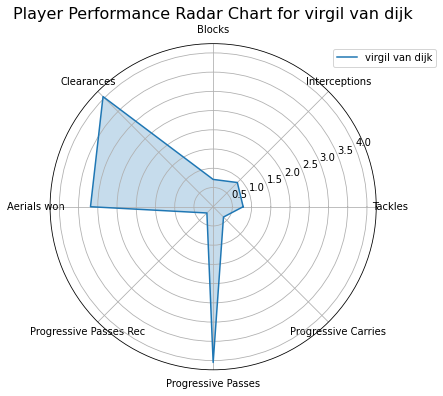


Data for virgil van dijk:
   Tackles  Interceptions  Blocks  Clearances  Aerials won  \
0     0.78           0.89    0.71        4.05         3.19   

   Progressive Passes Rec  Progressive Passes  Progressive Carries  
0                    0.23                4.05                 0.38  
Enter the player name to generate the radar chart (or 'exit' to quit): harry maguire


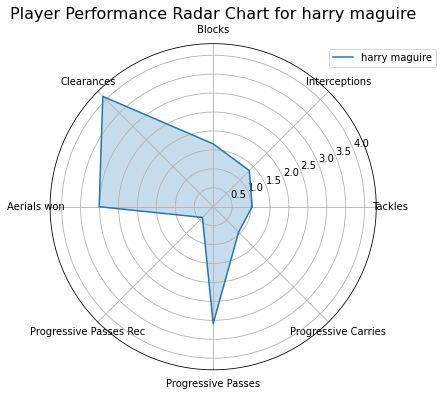


Data for harry maguire:
   Tackles  Interceptions  Blocks  Clearances  Aerials won  \
0     1.03           1.35    1.66        4.12         3.01   

   Progressive Passes Rec  Progressive Passes  Progressive Carries  
0                     0.4                3.09                 0.95  
Enter the player name to generate the radar chart (or 'exit' to quit): exit


In [4]:
# Metrics for the radar chart
metrics = ['Tackles', 'Interceptions', 'Blocks', 'Clearances', 'Aerials won', 'Progressive Passes Rec', 'Progressive Passes', 'Progressive Carries']

# List of player names for the radar chart
player_names = df['Player Name']

#print("Available players:")
#print(player_names.tolist())

while True:
    # Take player name as user input
    input_player = input("Enter the player name to generate the radar chart (or 'exit' to quit): ").strip()

    if input_player.lower() == 'exit':
        break

    # Check if the entered player name is valid (case-insensitive)
    if input_player.lower() in player_names.str.lower().values:
        # Selecting data for the radar chart for the specified player
        data = df[df['Player Name'].str.lower() == input_player.lower()][metrics]

        # Number of metrics for the radar chart
        num_metrics = len(metrics)

        # Calculate angles for the radar chart
        angles = np.linspace(0, 2 * np.pi, num_metrics, endpoint=False)

        # Close the plot (connect the last point to the first)
        angles = np.concatenate((angles, [angles[0]]))

        # Create a figure and axis for the radar chart
        fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

        # Plot the specified player's data on the radar chart
        player_data = data.values[0]
        values = np.concatenate((player_data, [player_data[0]]))  # Close the plot
        ax.plot(angles, values, label=input_player)

        # Fill the area under the lines to create the radar effect
        ax.fill(angles, values, alpha=0.25)

        # Customize the radar chart
        ax.set_thetagrids(angles[:-1] * 180 / np.pi, metrics)
        ax.set_title(f'Player Performance Radar Chart for {input_player}', fontsize=16)
        ax.grid(True)

        # Add a legend to the radar chart
        ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1))

        # Show the radar chart
        plt.show()
        
        # Display the data in tabular form
        player_table = pd.DataFrame(data.values, columns=metrics)
        print(f"\nData for {input_player}:")
        print(player_table)
        
    else:
        print("Invalid player name. Please enter a valid player name.")